# ---------------------------------`Salary Prediction`----------------------------------

![img](https://etimg.etb2bimg.com/photo/74487547.cms?mod=454549)

# Business Understanding

### 1. Business Backstory
In today's competitive job market, determining an appropriate salary is challenging for both employers and job seekers. Salaries vary depending on an individual's educational qualifications, job role, years of experience, and other factors.

Organizations need a data-driven approach to estimate salaries consistently, while job seekers want to understand the salary they might expect based on their professional profile.

To address this challenge, a Salary Prediction Machine Learning Model is developed using historical salary data. The model learns patterns between employee characteristics and salary to predict an estimated salary for a given profile.

## 2. Business Problem Statement
Organizations and job seekers need a reliable way to estimate salaries based on relevant employee characteristics. Without a data-driven approach, salary estimation may be inconsistent, making preliminary compensation planning and salary expectation analysis more difficult.

The business problem is to develop a machine learning model that learns patterns from historical salary data and predicts an estimated salary for a given profile.

## 3. Business Objectives
- Develop a data-driven system to estimate salaries based on employee characteristics.
- Identify patterns and relationships between job roles, education, experience, and salary.
- Compare multiple regression algorithms to identify a suitable predictive model.
- Evaluate prediction accuracy using MAE, RMSE, and R² score.
- Deploy the selected model through an interactive Gradio application.
- Provide users with quick salary estimates to support preliminary salary research and planning.

## 4. Business Constraints and Assumptions
- Data dependency: Prediction quality depends on the accuracy, size, and representativeness of the available dataset.
- Feature limitations: The model uses Gender, Education Level, Job Title, and Years of Experience; Age has been removed.
- Market variability: Actual salaries may vary by location, industry, company size, skills, and market demand, which may not be represented in the dataset.
- Model limitations: Predictions are estimates and may not match actual job offers.
- Fairness: Historical salary patterns may contain bias. Gender should not be used to justify unequal compensation.
- Deployment dependency: The Gradio application requires the trained model and its corresponding encoder to be available.

In [1]:
import pandas as pd,numpy as np
import warnings
warnings.filterwarnings('ignore')

In [2]:
df_raw = pd.read_csv("Salary Data.csv")
df_raw.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


### Data Understanding

In [3]:
df_raw.shape

(375, 6)

In [4]:
df_raw.dtypes

Age                    float64
Gender                  object
Education Level         object
Job Title               object
Years of Experience    float64
Salary                 float64
dtype: object

In [5]:
df_raw.columns

Index(['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience',
       'Salary'],
      dtype='object')

In [6]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    object 
 2   Education Level      373 non-null    object 
 3   Job Title            373 non-null    object 
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), object(3)
memory usage: 17.7+ KB


In [7]:
df_raw.describe()

,Age,Years of Experience,Salary
count,373.000000,373.000000,373.000000
mean,37.431635,10.030831,100577.345845
std,7.069073,6.557007,48240.013482
min,23.000000,0.000000,350.000000
25%,31.000000,4.000000,55000.000000
50%,36.000000,9.000000,95000.000000
75%,44.000000,15.000000,140000.000000
max,53.000000,25.000000,250000.000000


### Data Cleaning

In [8]:
df = df_raw.copy()

In [9]:
df["Job Title"].value_counts()

Job Title
Director of Marketing              12
Director of Operations             11
Senior Business Analyst            10
Senior Marketing Analyst            9
Senior Marketing Manager            9
                                   ..
Business Development Manager        1
Customer Service Representative     1
IT Manager                          1
Digital Marketing Manager           1
Junior Web Developer                1
Name: count, Length: 174, dtype: int64

In [10]:
df.isnull().sum()

Age                    2
Gender                 2
Education Level        2
Job Title              2
Years of Experience    2
Salary                 2
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(50)

In [12]:
df.drop_duplicates(inplace = True)

In [13]:
df = df.dropna(how="all")

In [14]:
df.drop("Age", axis=1, inplace=True)

In [15]:
print("Original Dataset:",df_raw.shape)
print("Cleaned Dataset:",df.shape)

Original Dataset: (375, 6)
Cleaned Dataset: (324, 5)


count    324.000000
mean      10.058642
std        6.650470
min        0.000000
25%        4.000000
50%        9.000000
75%       16.000000
max       25.000000
Name: Years of Experience, dtype: float64

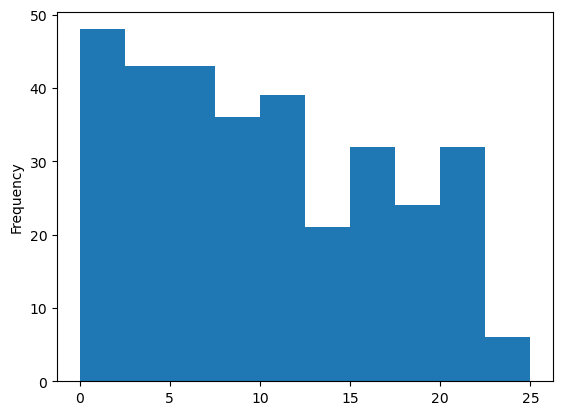

In [16]:
df["Years of Experience"].plot(kind = "hist")
df["Years of Experience"].describe()

<Axes: xlabel='Gender'>

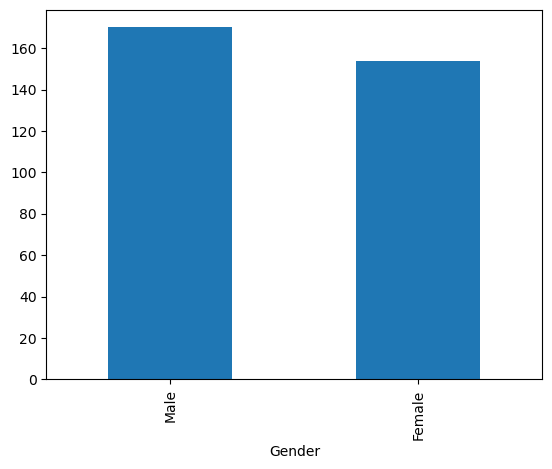

In [17]:
df["Gender"].value_counts().plot(kind = "bar")

<Axes: xlabel='Education Level'>

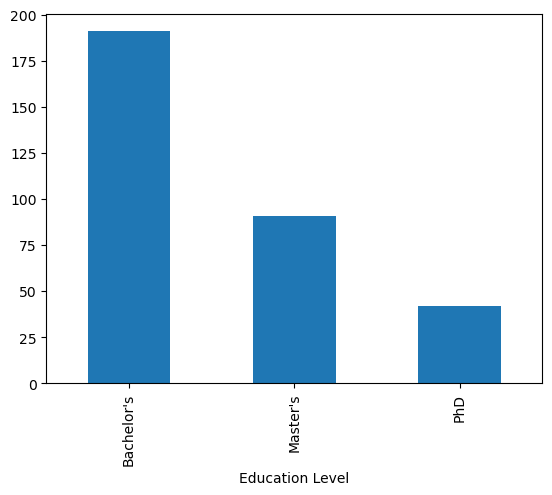

In [18]:
df["Education Level"].value_counts().plot(kind = "bar")

count       324.000000
mean      99985.648148
std       48652.271440
min         350.000000
25%       55000.000000
50%       95000.000000
75%      140000.000000
max      250000.000000
Name: Salary, dtype: float64

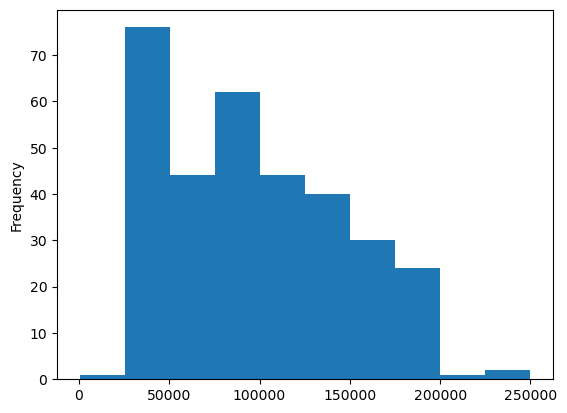

In [19]:
df["Salary"].plot(kind = "hist")
df["Salary"].describe()

In [20]:
df["Job Title"].unique()

array(['Software Engineer', 'Data Analyst', 'Senior Manager',
       'Sales Associate', 'Director', 'Marketing Analyst',
       'Product Manager', 'Sales Manager', 'Marketing Coordinator',
       'Senior Scientist', 'Software Developer', 'HR Manager',
       'Financial Analyst', 'Project Manager', 'Customer Service Rep',
       'Operations Manager', 'Marketing Manager', 'Senior Engineer',
       'Data Entry Clerk', 'Sales Director', 'Business Analyst',
       'VP of Operations', 'IT Support', 'Recruiter', 'Financial Manager',
       'Social Media Specialist', 'Software Manager', 'Junior Developer',
       'Senior Consultant', 'Product Designer', 'CEO', 'Accountant',
       'Data Scientist', 'Marketing Specialist', 'Technical Writer',
       'HR Generalist', 'Project Engineer', 'Customer Success Rep',
       'Sales Executive', 'UX Designer', 'Operations Director',
       'Network Engineer', 'Administrative Assistant',
       'Strategy Consultant', 'Copywriter', 'Account Manager',
      

<Axes: >

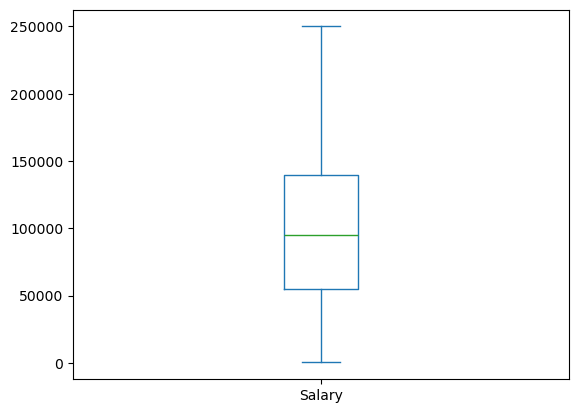

In [21]:
df["Salary"].plot(kind = "box")

<Axes: >

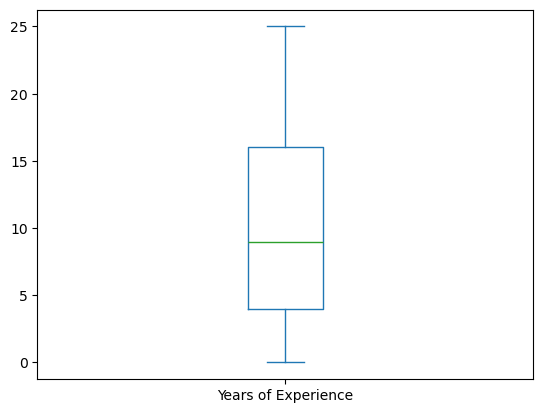

In [22]:
df["Years of Experience"].plot(kind = "box")

In [23]:
df["Education Level"].unique()

array(["Bachelor's", "Master's", 'PhD'], dtype=object)

#### Data encoding

In [24]:
# encode manually
df["Education Level"] = df["Education Level"].map({"Bachelor's":0,"Master's":1,"PhD":2})

In [25]:
df["Gender"] = df["Gender"].map({"Male":0,"Female":1})

In [26]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
df["Job Title"] = encoder.fit_transform(df["Job Title"])

In [27]:
print(df.head())
print(df.dtypes)
print(df.isnull().sum())

   Gender  Education Level  Job Title  Years of Experience    Salary
0       0                0        159                  5.0   90000.0
1       1                1         17                  3.0   65000.0
2       0                2        130                 15.0  150000.0
3       1                0        101                  7.0   60000.0
4       0                1         22                 20.0  200000.0
Gender                   int64
Education Level          int64
Job Title                int64
Years of Experience    float64
Salary                 float64
dtype: object
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64


In [28]:
df.dtypes

Gender                   int64
Education Level          int64
Job Title                int64
Years of Experience    float64
Salary                 float64
dtype: object

## Train-Test Split

In [29]:
X = df.drop(columns = ["Salary"]) # X contains inputs/features
X.head()

,Gender,Education Level,Job Title,Years of Experience
0,0,0,159,5.0
1,1,1,17,3.0
2,0,2,130,15.0
3,1,0,101,7.0
4,0,1,22,20.0


In [30]:
y = df["Salary"]
y.head()

0     90000.0
1     65000.0
2    150000.0
3     60000.0
4    200000.0
Name: Salary, dtype: float64

In [31]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 29
)

In [32]:
X_train.head()

,Gender,Education Level,Job Title,Years of Experience
126,1,1,121,9.0
137,1,0,64,4.0
289,0,0,69,4.0
128,1,0,82,4.0
98,1,1,97,10.0


In [33]:
print("The training input shape:", X_train.shape)
print("The training output shape:", y_train.shape)
print("The testing input shape:", X_test.shape)
print("The testing output shape:", y_test.shape)

The training input shape: (259, 4)
The training output shape: (259,)
The testing input shape: (65, 4)
The testing output shape: (65,)


## Model Training

#### Linear Regression

In [34]:
from sklearn.metrics import root_mean_squared_error
from sklearn.linear_model import LinearRegression

# Create model
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
print(y_pred_lr)

[ 99524.18993863 162994.29373482 175819.44467307  65767.56574739
  92927.96608125 145611.86338869  38097.56064638  57508.73743062
  71890.3712689   46159.74636496 171600.89360075  60641.04022928
  63631.54295213  48665.28473637  49015.27342596 119275.06162746
  57642.55663546 113360.34894613 182848.00749995 135543.54605445
  40499.10048449  55096.90380752 154498.61258973 163064.13308931
  49221.14912572 164284.10479421 105266.12541559 133450.81976599
  49118.21127584 145560.39446375 124772.16340514  87402.10431545
 105276.41920057 130524.39266708  43242.45659404  46292.50488639
  46149.45257997  81052.93129778  98783.13319307  95671.32219079
  37417.11015375 130728.05122642  43345.39444392  34191.00683319
  60622.66979973 151724.37512522 161542.8700515   51900.6211585
  84166.8636669  119367.70569236  39881.4733852  158686.28230708
 107453.71290937  81402.91998738  81454.38891232  73710.15407136
  68941.13945959  51293.28784421  86928.68597959  40447.63155955
  85816.95720088 163115.60

In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Model Evaluation
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression MAE:", mae_lr)
print("Linear Regression RMSE:", rmse_lr)
print("Linear Regression R2 Score:", r2_lr)

Linear Regression MAE: 12665.930405352548
Linear Regression RMSE: 16724.088797004486
Linear Regression R2 Score: 0.8837510794424023


#### KNN Regressor

In [36]:
from sklearn.neighbors import KNeighborsRegressor

In [37]:
knn = KNeighborsRegressor()
knn.fit(X_train,y_train)
y_pred_kn = knn.predict(X_test)
print(y_pred_kn)

[107000. 124000. 177000.  75000. 115000. 156000.  78000.  48000.  78000.
  40000. 153000.  49000.  61000.  49000.  43000. 120000.  57000. 127000.
 130000. 172000.  49000.  49000. 132000. 146000.  55000. 182000. 105000.
 101000.  50000. 145000. 124000. 107000. 107000. 124000.  42000.  41000.
  41000.  82000. 109000.  98000.  41000. 144000.  50000.  49000.  57000.
 128000. 170000.  53000.  94000. 124000.  57000. 112000. 122000.  90000.
  97000.  57000.  66000.  75000.  98000.  42000.  75000. 142000.  68000.
 102000.  44000.]


In [38]:
# Model Evaluation
mae_kn = mean_absolute_error(y_test, y_pred_kn)
rmse_kn = np.sqrt(mean_squared_error(y_test, y_pred_kn))
r2_kn = r2_score(y_test, y_pred_kn)

print("KNN MAE:", mae_kn)
print("KNN RMSE:", rmse_kn)
print("KNN R2 Score:", r2_kn)

KNN MAE: 13825.384615384615
KNN RMSE: 19835.13684969564
KNN R2 Score: 0.8364786734375625


#### Decision Tree Regressor

In [39]:
from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor()
dt.fit(X_train,y_train)
y_pred_dt = dt.predict(X_test)
print(y_pred_dt)

[100000. 190000. 170000.  80000. 120000. 140000.  45000.  45000.  60000.
  35000. 157500.  75000.  70000.  40000.  40000. 120000.  70000. 130000.
 190000. 180000.  40000.  45000. 140000. 160000.  40000. 190000. 105000.
 130000.  40000. 140000. 130000. 105000. 105000. 130000.  35000.  45000.
  40000.  80000. 130000. 120000.  40000. 140000.  35000.  35000.  65000.
 160000. 170000.  50000.  92500. 120000.  40000. 170000. 130000. 100000.
 100000.  90000.  70000.  80000.  80000.  40000.  45000. 160000.  75000.
  80000.  50000.]


In [40]:
# Model Evaluation
mae_dt = mean_absolute_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree MAE:", mae_dt)
print("Decision Tree RMSE:", rmse_dt)
print("Decision Tree R2 Score:", r2_dt)

Decision Tree MAE: 10533.076923076924
Decision Tree RMSE: 14012.6989109604
Decision Tree R2 Score: 0.9183892103016011


In [41]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print(y_pred_rf)

[103907.26190476 173100.         173814.16666667  56550.
 107145.77741703 142802.11538462  43450.          53410.
  66255.          36771.78571429 154339.16250416  69705.
  68983.33333333  43550.          39854.16666667 117783.63095238
  66672.70562771 124222.5        180082.91666667 168189.09090909
  40275.          48710.         142741.63919414 157042.83674659
  39355.95238095 184081.94805195 106341.76948052 130650.
  39280.95238095 138218.33333333 130785.          96693.45238095
 106241.76948052 130549.16666667  36600.          45239.16666667
  38978.33333333  81905.47619048 119667.92027417 102230.87301587
  39608.33333333 135602.11538462  35100.          37100.
  60507.03102453 156071.81547619 170306.90656566  54551.31673882
  91379.23520924 115397.02380952  43350.         164574.16666667
 123917.97979798  95236.58549784 103278.55519481  76350.
  66900.          55428.33333333  88056.25        40050.
  61972.22222222 156362.38802864  51121.38708514  89786.25
  47525.        ]


In [42]:
## Model Evaluation
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest MAE:", mae_rf)
print("Random Forest RMSE:", rmse_rf)
print("Random Forest R2 Score:", r2_rf)

Random Forest MAE: 9175.440466584696
Random Forest RMSE: 12444.148665947961
Random Forest R2 Score: 0.9356372812329166


## Model Evaluation

In [43]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "KNN Regressor", "Decision Tree", "Random Forest"],
    "MAE": [
        mae_lr,
        mae_kn,
        mae_dt,
        mae_rf
    ],
    "RMSE": [
        rmse_lr,
        rmse_kn,
        rmse_dt,
        rmse_rf
    ],
    "R2 Score": [
        r2_lr,
        r2_kn,
        r2_dt,
        r2_rf
    ]
})

print(results.sort_values("RMSE"))

               Model           MAE          RMSE  R2 Score
3      Random Forest   9175.440467  12444.148666  0.935637
2      Decision Tree  10533.076923  14012.698911  0.918389
0  Linear Regression  12665.930405  16724.088797  0.883751
1      KNN Regressor  13825.384615  19835.136850  0.836479


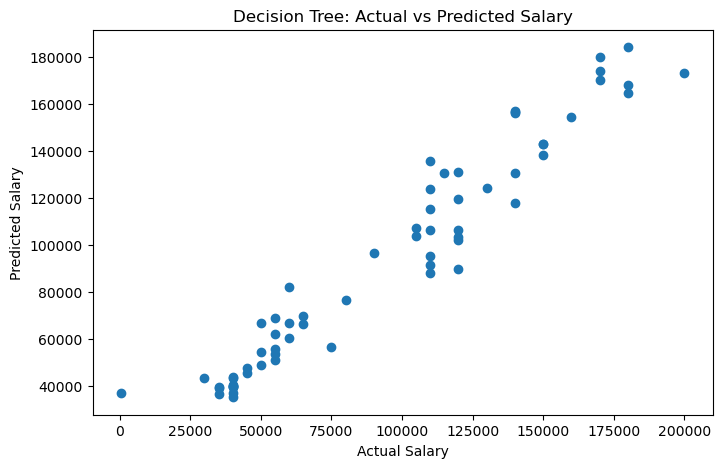

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_rf)
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Decision Tree: Actual vs Predicted Salary")

plt.show()

In [45]:
results = pd.DataFrame({
    "Actual Salary": y_test.values,
    "Predicted Salary": y_pred_rf
})

print(results.head())

   Actual Salary  Predicted Salary
0       105000.0     103907.261905
1       200000.0     173100.000000
2       170000.0     173814.166667
3        75000.0      56550.000000
4       105000.0     107145.777417


## Model Deployment

In [58]:
import pickle

with open("salary_model.pkl", "wb") as f:
    pickle.dump(rf, f)

with open("job_encoder.pkl", "wb") as f:
    pickle.dump(encoder, f)
# pickle.dump() = trained model is saved into model.pkl

In [59]:
with open("salary_model.pkl", "rb") as f:
    salary_model = pickle.load(f)

with open("job_encoder.pkl", "rb") as f:
    encoder = pickle.load(f)

In [60]:
import gradio as gr

def predict_salary(gender, education, job_title, experience):
    gender_map = {"Male": 0, "Female": 1}
    education_map = {"Bachelor's": 0, "Master's": 1, "PhD": 2}

    data = pd.DataFrame([[
        gender_map[gender],
        education_map[education],
        encoder.transform([job_title])[0],
        experience
    ]], columns=[
        "Gender",
        "Education Level",
        "Job Title",
        "Years of Experience"
    ])

    prediction = salary_model.predict(data)[0]

    return f"Predicted Salary: ₹{prediction:,.2f}"

In [61]:
iface = gr.Interface(
    fn=predict_salary,
    inputs=[
        gr.Dropdown(["Male", "Female"], label="Gender"),
        gr.Dropdown(
            ["Bachelor's", "Master's", "PhD"],
            label="Education Level"
        ),
        gr.Dropdown(encoder.classes_.tolist(), label="Job Title"),
        gr.Slider(0, 50, value=2, label="Years of Experience")
    ],
    outputs=gr.Textbox(label="Predicted Salary"),
    title="Salary Prediction App",
    description="Enter your details to predict your salary."
)

iface.launch(share = True)

* Running on local URL:  http://127.0.0.1:7864
* Running on public URL: https://a9df2d5dda3a7f0c75.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
